In [4]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers, models

In [5]:
df = pd.read_csv("AutoEncoder/ECG/ecg.csv", header=None)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4998, 141)


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [6]:
X = df.drop(140, axis=1)
y = df[140]

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

x_train = x_train[y_train == 1]

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (2335, 140)
Testing shape: (1000, 140)


In [8]:
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [9]:
encoder = models.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu")
])

decoder = models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(x_train.shape[1], activation="sigmoid")
])

model = models.Sequential([encoder, decoder])

In [10]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history = model.fit(
    x_train, x_train,
    validation_split=0.1,
    epochs=20,
    batch_size=512
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0243 - mae: 0.1272 - val_loss: 0.0238 - val_mae: 0.1244
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0227 - mae: 0.1219 - val_loss: 0.0218 - val_mae: 0.1166
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0202 - mae: 0.1120 - val_loss: 0.0194 - val_mae: 0.1074
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0175 - mae: 0.1017 - val_loss: 0.0171 - val_mae: 0.0991
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0150 - mae: 0.0924 - val_loss: 0.0150 - val_mae: 0.0913
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0129 - mae: 0.0844 - val_loss: 0.0135 - val_mae: 0.0847
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0114 - mae: 0.0775 - val_loss: 0.0123 - val_mae: 0.0795
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0104 - mae: 0.0728 - val_loss: 0.0116 - val_mae: 0.0761
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0097 - mae: 0.0695 - val_los

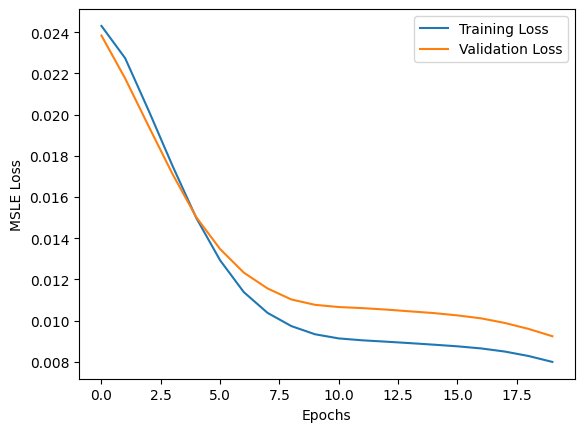

In [11]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSLE Loss")
plt.legend()
plt.show()

In [12]:
predictions = model.predict(x_train, verbose=0)
errors = tf.keras.losses.msle(x_train, predictions).numpy()
threshold = np.mean(errors) + np.std(errors)

predictions = model.predict(x_test, verbose=0)
errors = tf.keras.losses.msle(x_test, predictions).numpy()

anomalies = (errors > threshold).astype(int)
y_pred = 1 - anomalies

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Number of anomalies:", np.sum(anomalies))

Threshold: 0.008431719
Accuracy: 0.95
Number of anomalies: 458
